# 05 · Experiment design and impact sizing
**Target population:** first-time buyers (no purchase earlier in October) who cart an electronics
product. Notebook 02 shows they convert about 30 points below returning buyers, and the gap survives the
cart-logging bound. Notebook 03 shows the decision is made within minutes of carting.

**Hypothesis:** returning buyers already trust the store and have checkout details saved. First-time
buyers lack both, and some of the gap is friction and uncertainty that a message can reduce.
This is a hypothesis: the data shows *who* abandons, not *why*.

**Intervention:** an in-cart and checkout panel for first-time buyers showing the expected delivery
date, the returns policy and payment options, including installments.

In [1]:
import json, math, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "outputs/figures"
RESULTS = ROOT / "outputs/results.json"
results = json.loads(RESULTS.read_text())
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
SCALE = 10
DAYS = 31

In [2]:
tgt = results["survival"]["target"]
p0 = tgt["p0_7day"]
price = tgt["avg_cart_price"]
monthly_carts = tgt["n_first_carts_sample"] * SCALE
weekly_carts = monthly_carts / DAYS * 7
gap_pp = results["customer_split"]["gap_bound_pp"]  # conservative end of the gap
value_per_pp = monthly_carts * 0.01 * price
print(f"First-time electronics carts: {monthly_carts:,.0f}/month ({weekly_carts:,.0f}/week) store-wide; "
      f"7-day purchase rate p0 = {p0:.1%}; avg cart price ${price:,.0f}")
print(f"Each +1 point of 7-day conversion is worth ${value_per_pp / 1e6:,.2f}M revenue per month")

First-time electronics carts: 253,060/month (57,143/week) store-wide; 7-day purchase rate p0 = 46.5%; avg cart price $398
Each +1 point of 7-day conversion is worth $1.01M revenue per month


## Power analysis
Randomize by user, 50/50. Two-sided α = 0.05, power 0.8. MDEs are in absolute percentage points,
shown with the share of the (conservative) first-time vs returning gap each represents.

In [3]:
rows = []
for mde_pp in [1.0, 1.5, 2.0, 3.0]:
    es = proportion_effectsize(p0 + mde_pp / 100, p0)
    n = math.ceil(NormalIndPower().solve_power(es, alpha=0.05, power=0.8, ratio=1))
    rows.append({"mde_pp": mde_pp, "share_of_gap": round(mde_pp / gap_pp, 3), "relative_lift": round(mde_pp / 100 / p0, 4),
                 "n_per_arm": n, "weeks": max(2, math.ceil(2 * n / weekly_carts))})
power = pd.DataFrame(rows)
results["experiment"] = {"population": "first-time buyers carting electronics", "p0_7day": round(p0, 4),
                         "monthly_carts": int(monthly_carts), "weekly_carts": int(weekly_carts),
                         "avg_cart_price": price, "value_per_pp_month": round(value_per_pp, 0),
                         "power_table": power.to_dict("records")}
power

,mde_pp,share_of_gap,relative_lift,n_per_arm,weeks
0,1.0,0.036,0.0215,39097,2
1,1.5,0.054,0.0323,17386,2
2,2.0,0.072,0.0431,9785,2
3,3.0,0.108,0.0646,4352,2


## Impact sizing
Incremental revenue per month = carts × reach × lift (points) × average price.
- **Lift:** a share of the conservative gap closed, triangular 0 / 5% / 12%. The gap is mostly
  who the shoppers are, not anything a message can fix, so only a small share is assumed closable.
- **Reach:** share of first-time carts that render the panel (supported clients, installments
  available), uniform 85–100%.
- **Margin:** retail electronics, triangular 8 / 15 / 22%.

In [4]:
def revenue(reach, lift_pp):
    return monthly_carts * reach * lift_pp / 100 * price

scen = pd.DataFrame({"scenario": ["low", "base", "high"], "reach": [0.85, 0.92, 1.0],
                     "share_of_gap_closed": [0.02, 0.05, 0.10], "margin": [0.10, 0.15, 0.20]})
scen["lift_pp"] = (scen.share_of_gap_closed * gap_pp).round(2)
scen["incremental_revenue"] = revenue(scen.reach, scen.lift_pp).round(0)
scen["gross_profit"] = (scen.incremental_revenue * scen.margin).round(0)

rng = np.random.default_rng(0)
N = 100_000
reach = rng.uniform(0.85, 1.0, N)
lift_pp = rng.triangular(0.0, 0.05, 0.12, N) * gap_pp
margin = rng.triangular(0.08, 0.15, 0.22, N)
mc_rev = revenue(reach, lift_pp)
pct = lambda a: {f"p{q}": round(float(np.percentile(a, q)), 0) for q in (10, 50, 90)}
results["impact"] = {"scenarios": scen.to_dict("records"), "mc_revenue": pct(mc_rev),
                     "mc_gross_profit": pct(mc_rev * margin),
                     "mc_lift_pp": {f"p{q}": round(float(np.percentile(lift_pp, q)), 2) for q in (10, 50, 90)},
                     "assumptions": {"share_of_gap_closed": "triangular 0 / 5% / 12%", "reach": "uniform 85–100%",
                                     "margin": "triangular 8 / 15 / 22%", "gap_pp": gap_pp}}
print(results["impact"]["mc_revenue"], results["impact"]["mc_gross_profit"], results["impact"]["mc_lift_pp"])
scen

{'p10': 631878.0, 'p50': 1421135.0, 'p90': 2350158.0} {'p10': 89162.0, 'p50': 208071.0, 'p90': 365595.0} {'p10': 0.68, 'p50': 1.53, 'p90': 2.52}


,scenario,reach,share_of_gap_closed,margin,lift_pp,incremental_revenue,gross_profit
0,low,0.85,0.02,0.10,0.55,471412.0,47141.0
1,base,0.92,0.05,0.15,1.39,1289501.0,193425.0
2,high,1.00,0.10,0.20,2.77,2793180.0,558636.0


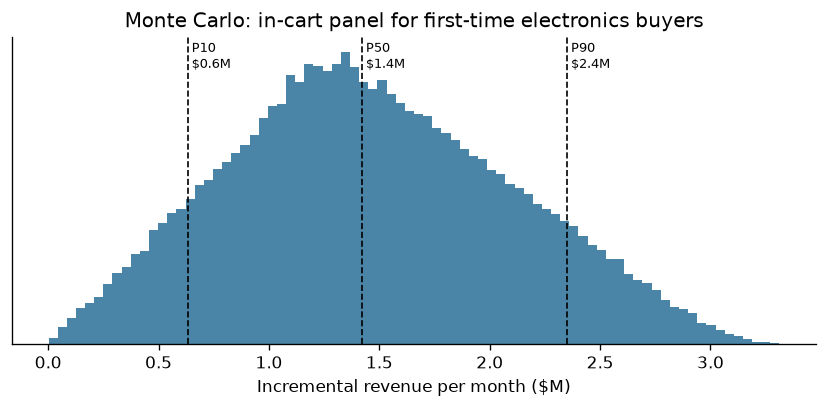

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(mc_rev / 1e6, bins=80, color="#2a6f97", alpha=0.85)
for q, v in results["impact"]["mc_revenue"].items():
    ax.axvline(v / 1e6, c="k", ls="--", lw=1); ax.text(v / 1e6, ax.get_ylim()[1] * 0.9, f" {q.upper()}\n ${v / 1e6:,.1f}M", fontsize=8)
ax.set_xlabel("Incremental revenue per month ($M)"); ax.set_yticks([])
ax.set_title("Monte Carlo: in-cart panel for first-time electronics buyers")
fig.tight_layout(); fig.savefig(FIG / "impact_monte_carlo.png"); plt.show()

In [6]:
RESULTS.write_text(json.dumps(results, indent=2, default=float))

9430